## Lưu ý về kết quả đã lưu

Mã augmentation từ cell 4 và 9 đã được đồng bộ theo chính sách của `build_wrn.ipynb` sau lượt chạy đang lưu trong notebook. Output cũ (test accuracy 84,95%; checkpoint epoch 26) thuộc cấu hình trước khi đồng bộ hoàn toàn. **Cần chạy lại từ đầu và cập nhật số liệu trước khi gọi đây là kết quả của protocol mới.** Resize lên 224×224 và chuẩn hóa ImageNet vẫn là bước đầu vào riêng cho EfficientNet pretrained.


In [12]:
# Cell 1 — Cài thư viện (chạy nếu môi trường chưa có)
!pip -q install timm scikit-learn seaborn tqdm

In [13]:
# Cell 2 — Import và cấu hình
import os
import pickle
import random
import copy
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
import timm

from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DATA_DIR = "/kaggle/input/datasets/hiu309/cifar100/cifar-100-python"
BATCH_SIZE = 32
EPOCHS = 30
VAL_RATIO = 0.10
PATIENCE = 4
NUM_WORKERS = 2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = DEVICE.type == "cuda"

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: Tesla T4


In [14]:
# Cell 3 — Dataset đọc CIFAR-100 dạng pickle
class CIFAR100PickleDataset(Dataset):
    def __init__(self, file_path, transform=None):
        self.transform = transform
        with open(file_path, "rb") as f:
            entry = pickle.load(f, encoding="latin1")
        self.data = entry["data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
        self.labels = np.asarray(entry["fine_labels"], dtype=np.int64)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        image = Image.fromarray(self.data[idx])
        label = int(self.labels[idx])
        if self.transform is not None:
            image = self.transform(image)
        return image, label

train_file = os.path.join(DATA_DIR, "train")
test_file = os.path.join(DATA_DIR, "test")
meta_file = os.path.join(DATA_DIR, "meta")

for path in [train_file, test_file, meta_file]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Không tìm thấy: {path}\n"
            "Hãy kiểm tra DATA_DIR và cấu trúc thư mục CIFAR-100 trên Kaggle."
        )

with open(meta_file, "rb") as f:
    meta = pickle.load(f, encoding="latin1")
classes = meta.get("fine_label_names", meta.get(b"fine_label_names"))
classes = [c.decode("utf-8") if isinstance(c, bytes) else c for c in classes]

print("Số lớp:", len(classes))
print("Một số lớp:", classes[:10])


Số lớp: 100
Một số lớp: ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle']


In [15]:
# Cell 4 — Cùng chính sách augmentation với WRN trên ảnh CIFAR-100 32x32
# Chia dữ liệu đúng chỉ số như build_wrn.ipynb: NumPy default_rng(42), 5.000 val đầu tiên.
# Resize 224 và ImageNet normalization là tiền xử lý riêng cho EfficientNet pretrained.
from torchvision.transforms import functional as TF

IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_aug_dataset = CIFAR100PickleDataset(train_file)
val_size = int(VAL_RATIO * len(train_aug_dataset))
permutation = np.random.default_rng(SEED).permutation(len(train_aug_dataset))
val_indices = permutation[:val_size].tolist()
train_indices = permutation[val_size:].tolist()
train_mean = train_aug_dataset.data[train_indices].mean(axis=(0, 1, 2), dtype=np.float64) / 255.0

class WRNImageAugment:
    """Jitter 80%; chọn một trong Cutout 25%, Erasing 25%, giữ nguyên 50%."""
    def __call__(self, image):
        if random.random() < 0.8:
            image = image + random.uniform(-0.05, 0.05)
            image = TF.adjust_contrast(image, random.uniform(0.9, 1.1))
            image = TF.adjust_saturation(image, random.uniform(0.9, 1.1))
            image = TF.adjust_hue(image, random.uniform(-0.02, 0.02))
            image = image.clamp(0.0, 1.0)
        choice = random.random()
        if choice < 0.25:
            height, width = image.shape[-2:]
            cy, cx = random.randrange(height), random.randrange(width)
            y1, y2 = max(0, cy - 4), min(height, cy + 4)
            x1, x2 = max(0, cx - 4), min(width, cx + 4)
            image = image.clone()
            image[:, y1:y2, x1:x2] = torch.as_tensor(
                train_mean, dtype=image.dtype
            ).view(3, 1, 1)
        elif choice < 0.50:
            _, height, width = image.shape
            area = random.uniform(0.02, 0.15) * height * width
            aspect = random.uniform(0.5, 2.0)
            erase_h = max(1, min(height, round((area / aspect) ** 0.5)))
            erase_w = max(1, min(width, round((area * aspect) ** 0.5)))
            top = random.randint(0, height - erase_h)
            left = random.randint(0, width - erase_w)
            image = image.clone()
            image[:, top:top + erase_h, left:left + erase_w] = torch.rand(
                (3, erase_h, erase_w), dtype=image.dtype
            )
        return image

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(32, padding=4, padding_mode="reflect"),
    transforms.ToTensor(),
    WRNImageAugment(),
    transforms.Resize((IMG_SIZE, IMG_SIZE), antialias=True),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE), antialias=True),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
train_aug_dataset.transform = train_transform
train_eval_dataset = CIFAR100PickleDataset(train_file, transform=eval_transform)
test_dataset = CIFAR100PickleDataset(test_file, transform=eval_transform)
train_dataset = Subset(train_aug_dataset, train_indices)
val_dataset = Subset(train_eval_dataset, val_indices)
print(f"Train: {len(train_dataset)} | Validation: {len(val_dataset)} | Test: {len(test_dataset)}")
print("Shared augmentation: flip, reflect crop, jitter, Cutout/Erasing, MixUp/CutMix")


Train: 45000 | Validation: 5000 | Test: 10000
Augmentation ảnh: RandomCrop, HorizontalFlip, Random Cutout, Random Noise Erasing
Augmentation theo batch: MixUp/CutMix (được áp dụng trong train loop)


In [16]:
# Cell 5 — DataLoaders
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
)

print(f"Batches — Train: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}")


Batches — Train: 1407 | Val: 157 | Test: 313


In [17]:
# Cell 6 — Khởi tạo EfficientNetV2-B0 pretrained
def get_model():
    model = timm.create_model(
        "tf_efficientnetv2_b0.in1k",
        pretrained=True,
        num_classes=100,
        drop_rate=0.3
    )
    return model.to(DEVICE)

model = get_model()
print("Đã khởi tạo EfficientNetV2-B0.")


Đã khởi tạo EfficientNetV2-B0.


In [18]:
# Cell 7 — Loss, optimizer và scheduler
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer = optim.AdamW(
    model.parameters(),
    lr=2e-5,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.2,
    patience=2,
    min_lr=1e-7
)

print("Đã thiết lập CrossEntropy + label smoothing, AdamW và scheduler.")


Đã thiết lập CrossEntropy + label smoothing, AdamW và scheduler.


In [19]:
# Cell 8 — Hàm đánh giá
def evaluate_model(model, loader, criterion=None, verbose=True):
    model.eval()
    total_loss = 0.0
    total = 0
    correct = 0
    all_labels, all_preds, all_probs = [], [], []

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Evaluating", leave=False):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            outputs = model(images)
            batch_size = labels.size(0)

            if criterion is not None:
                total_loss += criterion(outputs, labels).item() * batch_size

            predictions = outputs.argmax(dim=1)
            probabilities = torch.softmax(outputs, dim=1)

            total += batch_size
            correct += (predictions == labels).sum().item()
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(predictions.cpu().numpy())
            all_probs.extend(probabilities.cpu().numpy())

    results = {
        "loss": total_loss / total if criterion is not None and total else None,
        "accuracy": correct / total if total else 0.0,
        "y_true": np.asarray(all_labels),
        "y_pred": np.asarray(all_preds),
        "y_prob": np.asarray(all_probs),
    }

    if verbose:
        print(f"Accuracy: {results['accuracy'] * 100:.2f}%")
        if results["loss"] is not None:
            print(f"Loss: {results['loss']:.4f}")
    return results


In [20]:
# Cell 9 — Train loop: MixUp/CutMix + Early Stopping + checkpoint theo val_loss
# Cấu hình batch augmentation. Đặt xác suất về 0 nếu muốn tắt kỹ thuật tương ứng.
MIXUP_ALPHA = 0.5
CUTMIX_ALPHA = 1.0
MIXUP_PROB = 0.30
CUTMIX_PROB = 0.30


def sample_beta(alpha):
    """Lấy lambda từ phân phối Beta(alpha, alpha)."""
    concentration = torch.tensor(float(alpha), device=DEVICE)
    return torch.distributions.Beta(concentration, concentration).sample()


def apply_mixup(images, labels, alpha=MIXUP_ALPHA):
    indices = torch.randperm(images.size(0), device=images.device)
    lam = sample_beta(alpha)
    mixed_images = lam * images + (1.0 - lam) * images[indices]
    return mixed_images, labels, labels[indices], lam


def apply_cutmix(images, labels, alpha=CUTMIX_ALPHA):
    indices = torch.randperm(images.size(0), device=images.device)
    lam = sample_beta(alpha)
    batch_size, _, height, width = images.shape
    cut_ratio = torch.sqrt(1.0 - lam)
    cut_h = int(round((cut_ratio * height).item()))
    cut_w = int(round((cut_ratio * width).item()))
    center_y = random.randrange(height)
    center_x = random.randrange(width)
    y1 = max(0, center_y - cut_h // 2)
    y2 = min(height, center_y + (cut_h + 1) // 2)
    x1 = max(0, center_x - cut_w // 2)
    x2 = min(width, center_x + (cut_w + 1) // 2)

    mixed_images = images.clone()
    mixed_images[:, :, y1:y2, x1:x2] = images[indices, :, y1:y2, x1:x2]
    # Tính lambda thực tế theo diện tích patch sau khi cắt ở biên ảnh.
    kept = 1.0 - ((y2 - y1) * (x2 - x1) / float(height * width))
    return mixed_images, labels, labels[indices], kept


def train_model(model, train_loader, val_loader, criterion, optimizer,
                scheduler, epochs=30, patience=4,
                checkpoint_path="efficientnetv2_b0_cifar100_best.pth"):
    history = {
        "train_loss": [], "train_accuracy": [],
        "val_loss": [], "val_accuracy": []
    }

    best_val_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0
    best_state = None

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        total = 0
        correct_weighted = 0.0

        loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")
        for images, labels in loop:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            r = random.random()

            # Áp dụng tối đa một kỹ thuật theo batch: 30% MixUp, 30% CutMix,
            # 40% giữ ảnh gốc. Labels được trộn bằng loss có trọng số.
            if r < MIXUP_PROB:
                images, labels_a, labels_b, lam = apply_mixup(images, labels)
                mix_mode = "mixup"
            elif r < MIXUP_PROB + CUTMIX_PROB:
                images, labels_a, labels_b, lam = apply_cutmix(images, labels)
                mix_mode = "cutmix"
            else:
                labels_a, labels_b, lam = labels, labels, 1.0
                mix_mode = "none"

            optimizer.zero_grad(set_to_none=True)
            outputs = model(images)
            if mix_mode == "none":
                loss = criterion(outputs, labels_a)
                batch_correct = (outputs.argmax(dim=1) == labels_a).sum().item()
            else:
                loss = lam * criterion(outputs, labels_a) + (1.0 - lam) * criterion(outputs, labels_b)
                predictions = outputs.argmax(dim=1)
                batch_correct = (
                    lam * (predictions == labels_a).sum().item()
                    + (1.0 - lam) * (predictions == labels_b).sum().item()
                )
            loss.backward()
            optimizer.step()

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total += batch_size
            correct_weighted += batch_correct

            loop.set_postfix(
                loss=f"{total_loss / max(total, 1):.4f}",
                acc=f"{100 * correct_weighted / max(total, 1):.2f}%",
                aug=mix_mode
            )

        train_loss = total_loss / total
        train_acc = correct_weighted / total

        val_results = evaluate_model(model, val_loader, criterion=criterion, verbose=False)
        val_loss = val_results["loss"]
        val_acc = val_results["accuracy"]

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)

        scheduler.step(val_loss)
        current_lr = optimizer.param_groups[0]["lr"]

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss={train_loss:.4f}, Train Acc={train_acc*100:.2f}% | "
            f"Val Loss={val_loss:.4f}, Val Acc={val_acc*100:.2f}% | "
            f"LR={current_lr:.2e}"
        )

        if val_loss < best_val_loss - 1e-4:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save(best_state, checkpoint_path)
            epochs_without_improvement = 0
            print(f"  -> Lưu checkpoint tốt nhất (epoch {best_epoch}, val_loss={best_val_loss:.4f})")
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(f"Early stopping: validation loss không cải thiện trong {patience} epoch.")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    print(f"Epoch tốt nhất: {best_epoch} | Best Val Loss: {best_val_loss:.4f}")
    return history

In [21]:
# Cell 10 — Huấn luyện
history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=EPOCHS,
    patience=PATIENCE,
    checkpoint_path="efficientnetv2_b0_cifar100_best.pth"
)


Epoch 1/30:   0%|          | 0/1407 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch 1/30 | Train Loss=4.3649, Train Acc=7.85% | Val Loss=3.5018, Val Acc=31.26% | LR=2.00e-05
  -> Lưu checkpoint tốt nhất (epoch 1, val_loss=3.5018)


Epoch 2/30:   0%|          | 0/1407 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e63af4020c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e63af4020c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 29/30 | Train Loss=1.6528, Train Acc=77.28% | Val Loss=1.2970, Val Acc=84.80% | LR=8.00e-07


Epoch 30/30:   0%|          | 0/1407 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch 30/30 | Train Loss=1.6651, Train Acc=77.08% | Val Loss=1.2837, Val Acc=85.14% | LR=8.00e-07
Early stopping: validation loss không cải thiện trong 4 epoch.
Epoch tốt nhất: 26 | Best Val Loss: 1.2671


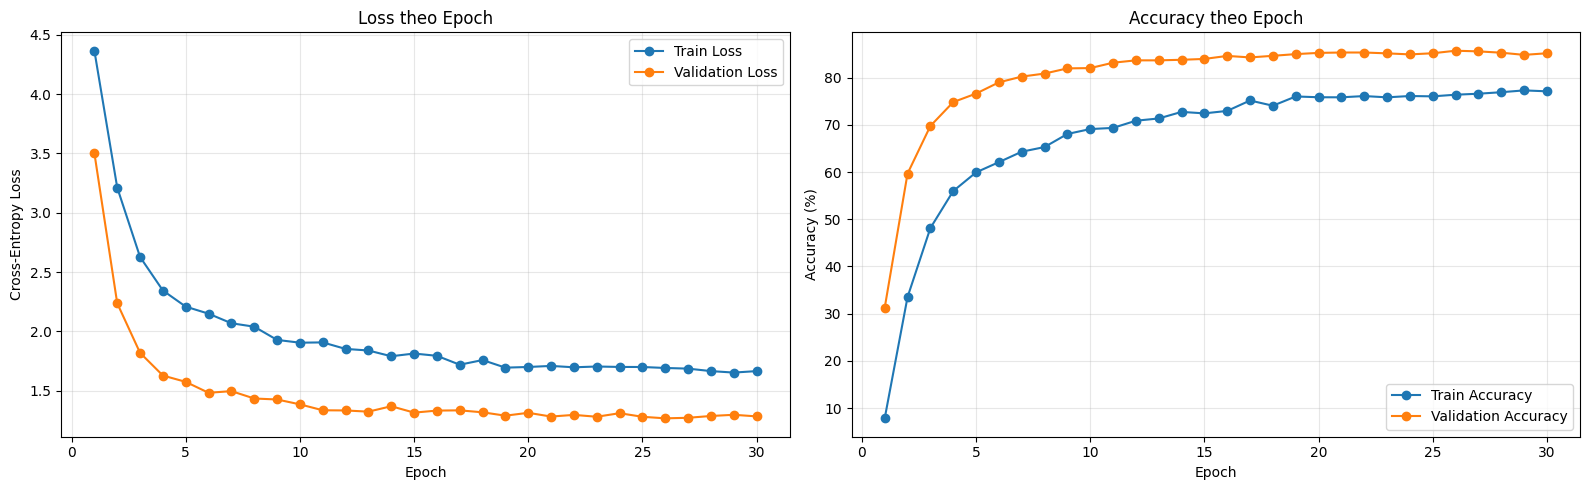

In [34]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# Chuyển Tensor trên GPU về CPU và đổi thành NumPy
def to_numpy(values):
    result = []
    for value in values:
        if torch.is_tensor(value):
            value = value.detach().cpu().item()
        result.append(value)
    return np.asarray(result, dtype=float)


# Số epoch đã thực sự huấn luyện
train_loss = to_numpy(history["train_loss"])
val_loss = to_numpy(history["val_loss"])
train_acc = to_numpy(history["train_accuracy"])
val_acc = to_numpy(history["val_accuracy"])

epochs_range = range(1, len(train_loss) + 1)

# Tạo 2 biểu đồ
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# =========================
# 1. Loss theo Epoch
# =========================
axes[0].plot(
    epochs_range, train_loss,
    marker="o", label="Train Loss"
)
axes[0].plot(
    epochs_range, val_loss,
    marker="o", label="Validation Loss"
)

axes[0].set_title("Loss theo Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# =========================
# 2. Accuracy theo Epoch
# =========================
axes[1].plot(
    epochs_range, train_acc * 100,
    marker="o", label="Train Accuracy"
)
axes[1].plot(
    epochs_range, val_acc * 100,
    marker="o", label="Validation Accuracy"
)

axes[1].set_title("Accuracy theo Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
# Cell 12 — Nạp checkpoint tốt nhất và đánh giá test đúng một lần
model_test = get_model()
state = torch.load("efficientnetv2_b0_cifar100_best.pth", map_location=DEVICE)
model_test.load_state_dict(state)
model_test.eval()

print("=== KẾT QUẢ TRÊN TẬP TEST ===")
test_results = evaluate_model(model_test, test_loader, criterion=criterion)


=== KẾT QUẢ TRÊN TẬP TEST ===


Evaluating:   0%|          | 0/313 [00:00<?, ?it/s]

Accuracy: 84.95%
Loss: 1.2755


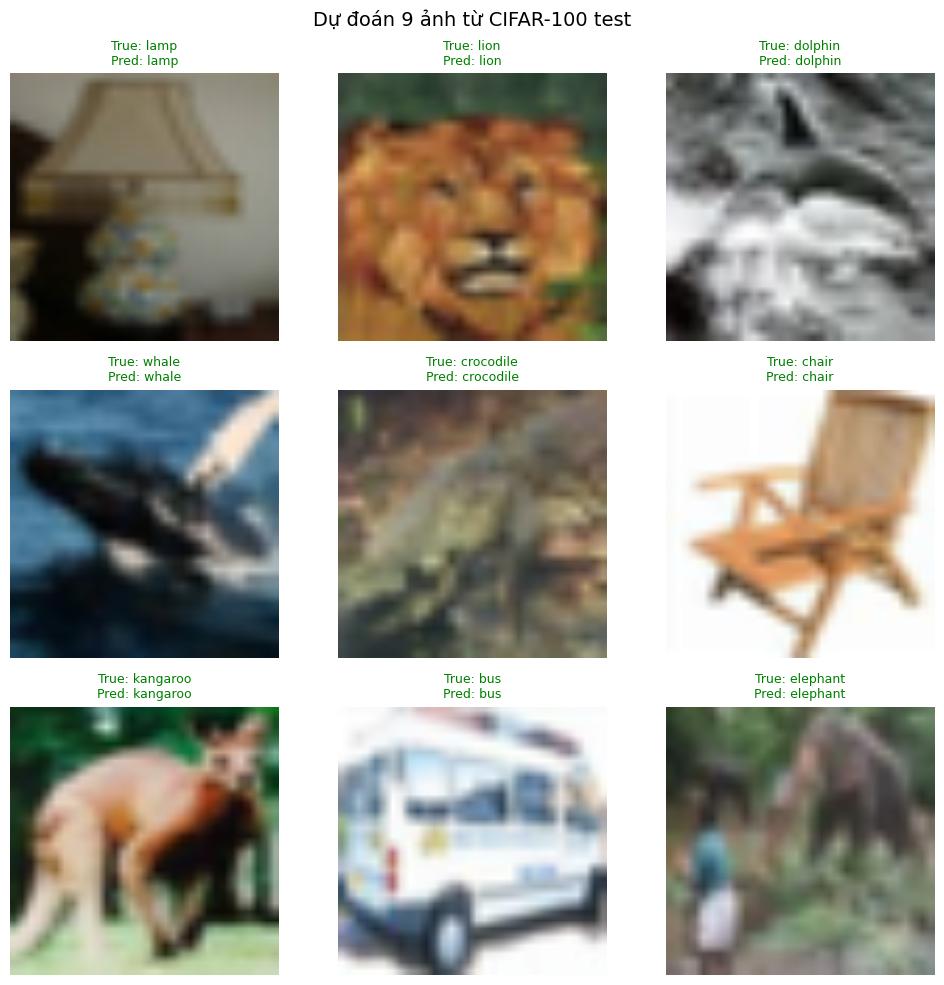

In [33]:
# Cell 13 — Hiển thị dự đoán 9 ảnh test
indices = random.sample(range(len(test_dataset)), 9)
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
axes = axes.flatten()

mean = np.array(IMAGENET_MEAN)
std = np.array(IMAGENET_STD)

model_test.eval()
for i, idx in enumerate(indices):
    image, label = test_dataset[idx]
    with torch.no_grad():
        output = model_test(image.unsqueeze(0).to(DEVICE))
        pred = output.argmax(dim=1).item()

    img = image.cpu().numpy().transpose(1, 2, 0)
    img = np.clip(img * std + mean, 0, 1)

    axes[i].imshow(img)
    axes[i].set_title(
        f"True: {classes[label]}\nPred: {classes[pred]}",
        color="green" if pred == label else "red",
        fontsize=9
    )
    axes[i].axis("off")

plt.suptitle("Dự đoán 9 ảnh từ CIFAR-100 test", fontsize=14)
plt.tight_layout()
plt.show()


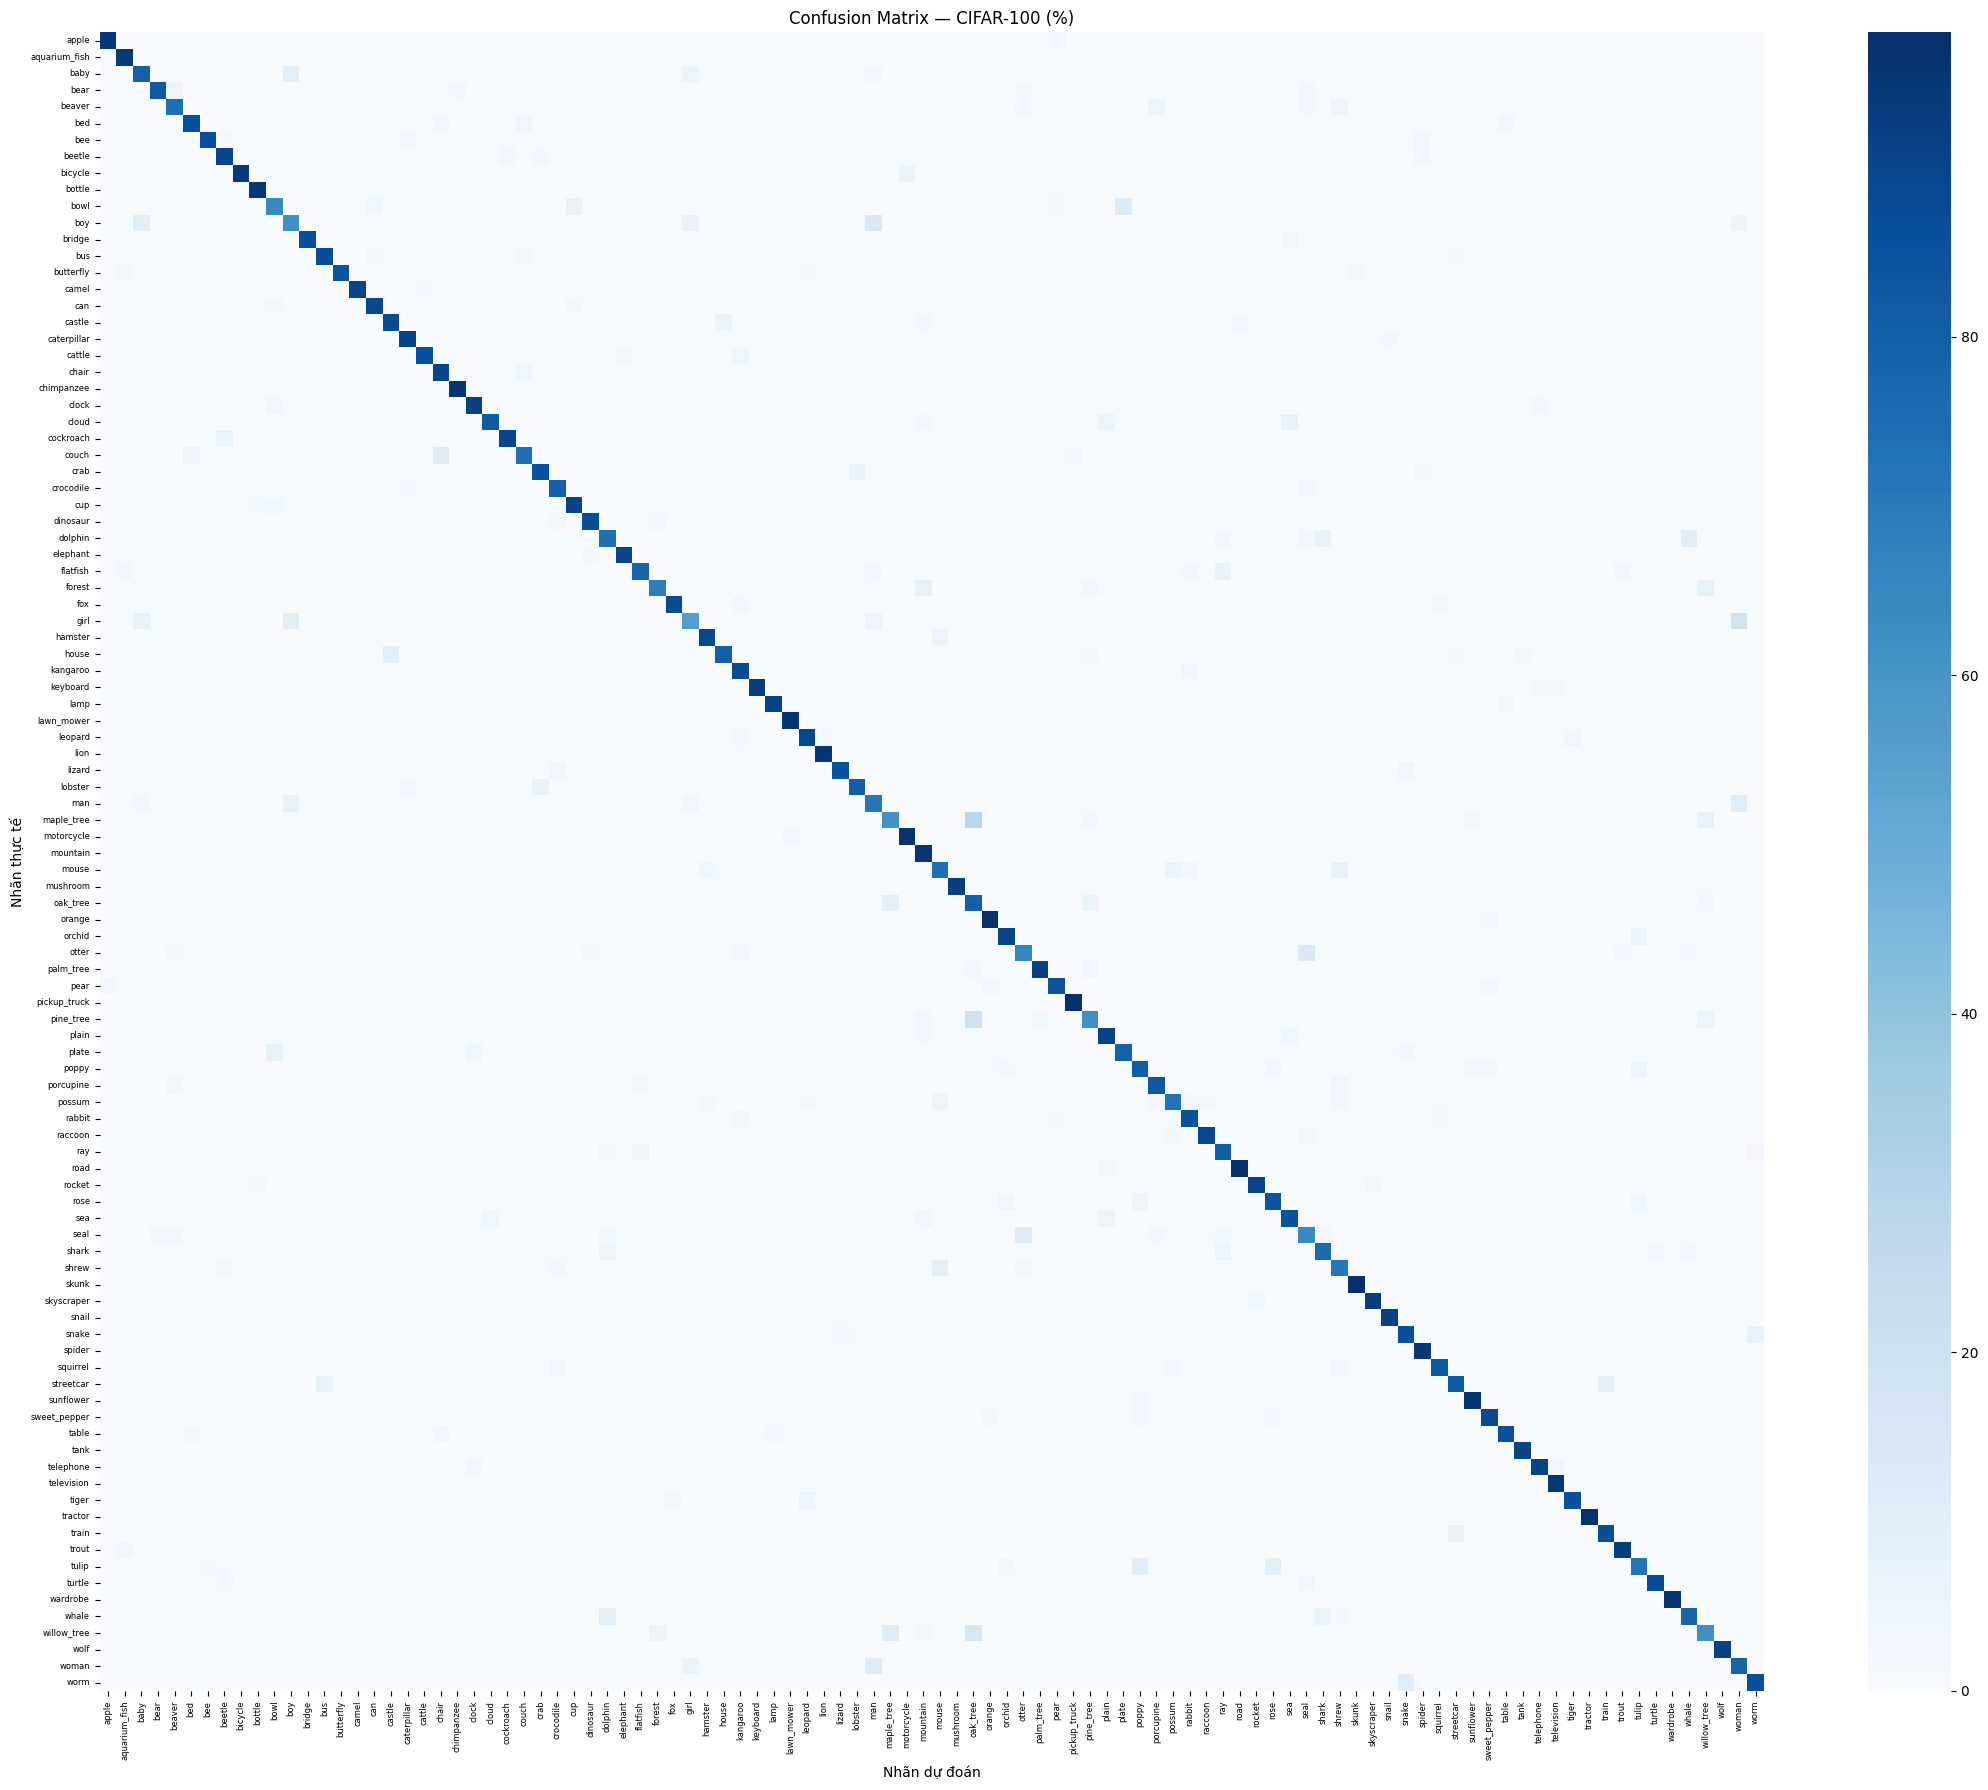

In [25]:
# Cell 14 — Confusion Matrix (chuẩn hóa theo phần trăm)
y_true = test_results["y_true"]
y_pred = test_results["y_pred"]

cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(classes)))
cm_normalized = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1) * 100

plt.figure(figsize=(22, 18))
sns.heatmap(
    cm_normalized,
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes,
    cbar=True
)
plt.title("Confusion Matrix — CIFAR-100 (%)")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)
plt.tight_layout()
plt.show()


In [35]:
# Cell 15 — Báo cáo precision/recall/F1 theo lớp (tùy chọn)
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(classes)),
    target_names=classes,
    digits=3,
    zero_division=0
))


               precision    recall  f1-score   support

        apple      0.950     0.950     0.950       100
aquarium_fish      0.870     0.940     0.904       100
         baby      0.745     0.790     0.767       100
         bear      0.828     0.820     0.824       100
       beaver      0.787     0.740     0.763       100
          bed      0.887     0.860     0.873       100
          bee      0.896     0.860     0.878       100
       beetle      0.833     0.900     0.865       100
      bicycle      0.949     0.940     0.945       100
       bottle      0.941     0.950     0.945       100
         bowl      0.739     0.650     0.691       100
          boy      0.674     0.620     0.646       100
       bridge      0.956     0.860     0.905       100
          bus      0.897     0.870     0.883       100
    butterfly      0.903     0.840     0.870       100
        camel      0.938     0.900     0.918       100
          can      0.848     0.890     0.868       100
       ca